# Customer Churn: Complete Analysis in Google Colab
### Segmentation + chi-square tests + deeper analysis + prediction models + high-risk customers

Runs a complete churn analysis for `Customer-Churn-Records.csv` (10,000 customers). **Run the cells from top to bottom.** Every step only uses what an earlier step has already created, and all settings you may want to change are in one cell at the top (Step 1).

| Part | Steps | Question it answers | What you get |
|---|---|---|---|
| **A. Setup** | 1-3 | Is the data clean? | Settings, upload, validation, cleaning, baseline churn rate |
| **B. Segments and chi-square** | 4-6 | *Who* churns? | A segment table, chart and chi-square test for every feature, then a ranked summary |
| **C. Deeper analysis** | 7-11 | *How* do churners differ? | Churned vs retained, country x age, financial stability, high-value customers and revenue risk, the five KPIs |
| **D. Prediction models** | 12-17 | *Who will leave next?* | Leakage check, five models compared, confusion matrix for the best one, threshold table, SHAP (optional) |
| **E. High-risk customers** | 18-20 | *Whom do we contact first?* | Risk tiers, who the high-risk customers are and why, and `high_risk_customers.csv` |

---
# Part A. Setup
## Step 1. Libraries and settings
Colab already has the libraries installed. The second block holds **every setting used later**: change a value here and re-run from this cell downwards.

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.base import clone
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, confusion_matrix, classification_report,
                             accuracy_score, precision_score, recall_score, f1_score)

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.figsize": (8, 3.8), "axes.spines.top": False, "axes.spines.right": False})
BLUE, GREY = "#2a78d6", "#b9b8b0"

# ---------------- settings you can change ----------------
SEED = 42                    # makes every random step repeatable
HIGH_VALUE_BALANCE = 100_000 # a balance above this counts as high-value (Steps 10, 11)
THRESHOLD = 0.5              # a customer is flagged as leaving when the probability is at least this (Steps 14, 16)
HIGH_RISK_SHARE = 0.20       # top 20% of customers by risk = High tier (Step 18)
MEDIUM_RISK_SHARE = 0.30     # next 30% = Medium tier

## Step 2. Load the data
In Colab a file chooser opens: pick `Customer-Churn-Records.csv`. Outside Colab the file is read from the same folder.

In [2]:
try:
    from google.colab import files          # only exists inside Colab
    uploaded = files.upload()               # choose Customer-Churn-Records.csv
    FILE = next(iter(uploaded))
except ImportError:
    FILE = "Customer-Churn-Records.csv"     # running outside Colab: file in the same folder

df = pd.read_csv(FILE)
# Normalize target column if named 'Exited'
if 'Exited' in df.columns and 'Churn' not in df.columns:
    df['Churn'] = df['Exited']

print(df.shape)
df.head()

Saving Customer-Churn-Records.csv to Customer-Churn-Records.csv
(10000, 19)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned,Churn
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425,0


## Step 3. Validate, clean and set the churn baseline
**Validation:** missing values, duplicate IDs, binary fields (`HasCrCard`, `IsActiveMember`, `Churn`) holding only 0/1, engagement and product fields inside plausible ranges, and a check that the churn label is correct.

**Cleaning:** the surname is removed because it identifies people and tells us nothing about churn.

**How to read it:** every `Out of range` count should be 0 and every 0/1 check should say `True`. A warning about `Complain` means it almost equals the churn label; it is flagged again in Step 6 and removed from the models in Step 12.

In [5]:
id_col = "CustomerId" if "CustomerId" in df.columns else ("CustomerID" if "CustomerID" in df.columns else None)
print("Rows, columns:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
if id_col:
    print("Duplicate customer IDs:", int(df[id_col].duplicated().sum()))

print("\n1) Binary fields hold only 0/1")
for c in [c for c in ["HasCrCard", "IsActiveMember", "Exited", "Churn", "Complain"] if c in df.columns]:
    print(f"   {c:15s} {set(df[c].dropna().unique()) <= {0, 1}}")

print("\n2) Engagement and product fields are in a plausible range")
limits = {"Age": (18, 100), "CreditScore": (300, 900), "Tenure": (0, 50), "Balance": (0, None), "NumOfProducts": (1, 4),
          "EstimatedSalary": (0, None), "Satisfaction Score": (1, 5), "Point Earned": (0, None)}
rows = []
for c, (low_lim, high_lim) in limits.items():
    if c in df.columns:
        bad = int((df[c] < low_lim).sum() + ((df[c] > high_lim).sum() if high_lim is not None else 0))
        rows.append({"Field": c, "Min": df[c].min(), "Max": df[c].max(),
                     "Expected": f"{low_lim} to {high_lim if high_lim is not None else 'no limit'}", "Out of range": bad})
display(pd.DataFrame(rows))

print("3) Churn label")
if "Exited" in df.columns:
    print("   Churn equals Exited in every row:", bool((df.Churn == df.Exited).all()))
print("   Churn only 0/1:", set(df.Churn.unique()) <= {0, 1})
if "Complain" in df.columns and (df.Complain == df.Churn).mean() > 0.99:
    print("   WARNING: Complain matches Churn in over 99% of rows. It is almost the same field as the target.")

df = df.drop(columns=["Surname"], errors="ignore")       # cleaning: remove the non-analytical field
print("\nSurname removed:", "Surname" not in df.columns)

OVERALL = df.Churn.mean() * 100
print(f"\nOverall churn rate: {OVERALL:.1f}%  ({int(df.Churn.sum()):,} of {len(df):,} customers)")
BASE_RATE = df.Churn.mean()

Rows, columns: (10000, 25)
Missing values: 0
Duplicate customer IDs: 0

1) Binary fields hold only 0/1
   HasCrCard       True
   IsActiveMember  True
   Exited          True
   Churn           True
   Complain        True

2) Engagement and product fields are in a plausible range


,Field,Min,Max,Expected,Out of range
0,Age,18.00,92.00,18 to 100,0
1,CreditScore,350.00,850.00,300 to 900,0
2,Tenure,0.00,10.00,0 to 50,0
3,Balance,0.00,250898.09,0 to no limit,0
4,NumOfProducts,1.00,4.00,1 to 4,0
5,EstimatedSalary,11.58,199992.48,0 to no limit,0
6,Satisfaction Score,1.00,5.00,1 to 5,0
7,Point Earned,119.00,1000.00,0 to no limit,0


3) Churn label
   Churn equals Exited in every row: True
   Churn only 0/1: True

Surname removed: True

Overall churn rate: 20.4%  (2,038 of 10,000 customers)


---
# Part B. Who churns: segment tables and chi-square tests
## Step 4. Create the grouped fields and the reusable functions
**Grouped fields (created once, used in every later step):** age group, credit band, tenure group, balance group, salary quartile and an Active / Inactive label.

**Functions (run once):** build a segment table, run the chi-square test and draw a chart for any feature. The tables are also saved in `SEG_TABLES`, so the KPIs in Step 11 reuse them instead of recalculating.

In [4]:
# ---- grouped fields (defined once) ----
BAL_ORDER = ["Zero", "Low (1-50k)", "Medium (50-100k)", "High (100k+)"]
df["AgeGroup"] = pd.cut(df.Age, bins=[0, 29, 45, 60, 200], labels=["<30", "30-45", "46-60", "60+"])
df["CreditBand"] = pd.cut(df.CreditScore, bins=[0, 579, 739, 900], labels=["Low (<580)", "Medium (580-739)", "High (740+)"])
df["TenureGroup"] = pd.cut(df.Tenure, bins=[-1, 2, 6, 100], labels=["New (0-2y)", "Mid-term (3-6y)", "Long-term (7y+)"])
df["BalanceGroup"] = pd.Categorical(np.select(
    [df.Balance == 0, (df.Balance > 0) & (df.Balance <= 50000), (df.Balance > 50000) & (df.Balance <= 100000), df.Balance > 100000],
    BAL_ORDER, default="Unknown"), categories=BAL_ORDER, ordered=True)
df["SalaryQuartile"] = pd.qcut(df.EstimatedSalary, 4, labels=["Q1 lowest", "Q2", "Q3", "Q4 highest"])
df["Activity"] = np.where(df.IsActiveMember == 1, "Active", "Inactive")
GROUPED = ["AgeGroup", "CreditBand", "TenureGroup", "BalanceGroup", "SalaryQuartile", "Activity"]   # kept out of the models in Step 12

# ---- reusable functions ----
RESULTS = []        # one row per tested feature (chi-square summary)
SEG_TABLES = {}     # the segment table of every tested feature

def cramers_v_from(chi2, n, shape):
    """Strength of the link between a feature and churn, from 0 (none) to 1 (perfect)."""
    return float(np.sqrt(chi2 / (n * (min(shape) - 1))))

def segment_table(seg):
    g = df.groupby(seg, observed=True).agg(
        Customers=("Churn", "size"), Churned=("Churn", "sum"),
        ChurnRate=("Churn", "mean"), AvgBalance=("Balance", "mean"),
    )
    g["BalanceLost"] = df[df.Churn == 1].groupby(seg[df.Churn == 1], observed=True).Balance.sum()
    g["BalanceLost"] = g.BalanceLost.fillna(0)
    g["ChurnRate"] = g.ChurnRate * 100
    g["ShareOfCustomers"] = g.Customers / len(df) * 100
    g["ShareOfChurners"] = g.Churned / df.Churn.sum() * 100
    g["RiskIndex"] = g.ChurnRate / OVERALL * 100
    g.index.name = seg.name
    return g[["Customers", "Churned", "ChurnRate", "ShareOfCustomers", "ShareOfChurners",
              "RiskIndex", "AvgBalance", "BalanceLost"]].round(1)

def chi2_test(seg):
    ct = pd.crosstab(seg, df.Churn)
    chi2, p, dof, expected = chi2_contingency(ct)
    v = cramers_v_from(chi2, ct.values.sum(), ct.shape)
    low_share = (expected < 5).mean() * 100
    return {"chi2": round(chi2, 2), "dof": int(dof), "p_value": p, "cramers_v": round(v, 3),
            "min_expected": round(expected.min(), 1), "cells_below_5_pct": round(low_share, 1)}

def strength(v):
    return "negligible" if v < 0.05 else "weak" if v < 0.10 else "moderate" if v < 0.20 else "strong"

def analyze(feature, show_chart=True):
    seg = df[feature].astype("category")
    seg.name = feature
    table = segment_table(seg)
    test = chi2_test(seg)
    significant = test["p_value"] < 0.05
    reliable = test["cells_below_5_pct"] <= 20

    print(f"=== {feature} ===")
    display(table)
    print(f"Chi-square = {test['chi2']}, dof = {test['dof']}, p-value = {test['p_value']:.4g}, "
          f"Cramer's V = {test['cramers_v']} ({strength(test['cramers_v'])})")
    print("Verdict:", "churn DIFFERS across segments (significant)" if significant
          else "no significant difference in churn across segments")
    if not reliable:
        print(f"Caution: {test['cells_below_5_pct']}% of cells have expected counts below 5.")

    if show_chart:
        colors = [BLUE if r > OVERALL else GREY for r in table.ChurnRate]
        ax = table.ChurnRate.plot(kind="bar", color=colors, rot=20 if len(table) > 5 else 0)
        ax.axhline(OVERALL, ls="--", color="black", lw=1)
        ax.set_ylabel("Churn rate (%)"); ax.set_xlabel(""); ax.set_title(f"Churn rate by {feature} (dashed = overall {OVERALL:.1f}%)")
        for i, v in enumerate(table.ChurnRate):
            ax.text(i, v + 0.3, f"{v:.1f}", ha="center", fontsize=9)
        plt.tight_layout(); plt.show()

    SEG_TABLES[feature] = table
    RESULTS.append({"Feature": feature, "Segments": len(table), "ChurnRateMin": table.ChurnRate.min(),
                    "ChurnRateMax": table.ChurnRate.max(), **test,
                    "Significant": "Yes" if significant else "No", "Strength": strength(test["cramers_v"]),
                    "Reliable": "Yes" if reliable else "No"})
    return table

## Step 5. Segment table and chi-square test for every feature
One loop runs the same analysis for each feature: country, gender, age, tenure, credit score, balance, salary, activity, products held, credit card, satisfaction score, card type and complaints (the fields that exist in your file).

**How to read each block**
- **Segment table:** how many customers are in each group, how many left (`ChurnRate`), the group's share of all churners next to its share of customers, and the `RiskIndex` (100 = average, 150 = one and a half times the average).
- **Chi-square test:** a `p-value` below 0.05 means churn really differs between groups. **Cramér's V** says how strongly: below 0.05 negligible, 0.05-0.10 weak, 0.10-0.20 moderate, above 0.20 strong.
- **Chart:** blue bars are above the overall churn rate, grey bars at or below it.

=== Geography ===


,Customers,Churned,ChurnRate,ShareOfCustomers,ShareOfChurners,RiskIndex,AvgBalance,BalanceLost
Geography,,,,,,,,
France,5014,811,16.2,50.1,39.8,79.4,62092.6,57759182.0
Germany,2509,814,32.4,25.1,39.9,159.2,119730.1,97973915.5
Spain,2477,413,16.7,24.8,20.3,81.8,61818.1,29948014.6


Chi-square = 300.63, dof = 2, p-value = 5.246e-66, Cramer's V = 0.173 (moderate)
Verdict: churn DIFFERS across segments (significant)


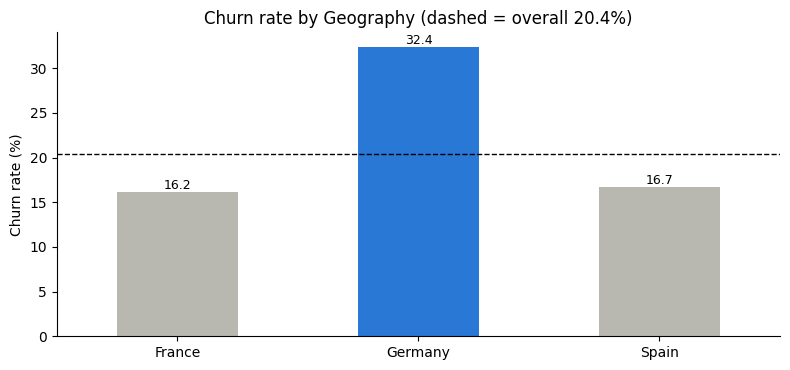

=== Gender ===


,Customers,Churned,ChurnRate,ShareOfCustomers,ShareOfChurners,RiskIndex,AvgBalance,BalanceLost
Gender,,,,,,,,
Female,4543,1139,25.1,45.4,55.9,123.0,75659.4,101412732.2
Male,5457,899,16.5,54.6,44.1,80.8,77174.0,84268379.9


Chi-square = 112.4, dof = 1, p-value = 2.925e-26, Cramer's V = 0.106 (moderate)
Verdict: churn DIFFERS across segments (significant)


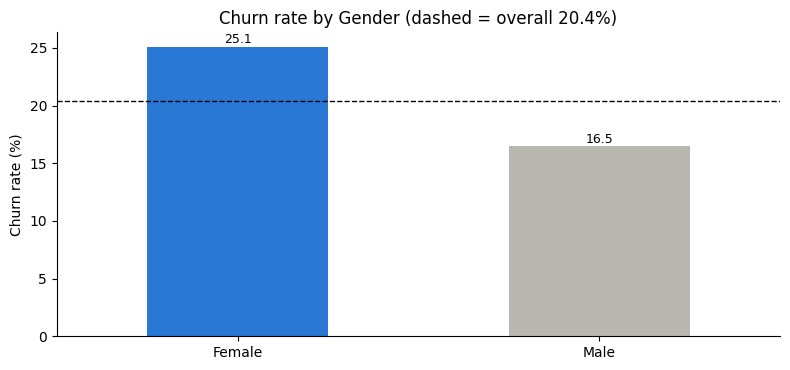

=== AgeGroup ===


,Customers,Churned,ChurnRate,ShareOfCustomers,ShareOfChurners,RiskIndex,AvgBalance,BalanceLost
AgeGroup,,,,,,,,
<30,1641,124,7.6,16.4,6.1,37.1,73698.7,12448473.1
30-45,6248,957,15.3,62.5,47.0,75.2,75951.3,87492258.5
46-60,1647,842,51.1,16.5,41.3,250.9,81500.5,75172453.6
60+,464,115,24.8,4.6,5.6,121.6,75742.6,10567926.9


Chi-square = 1229.89, dof = 3, p-value = 2.403e-266, Cramer's V = 0.351 (strong)
Verdict: churn DIFFERS across segments (significant)


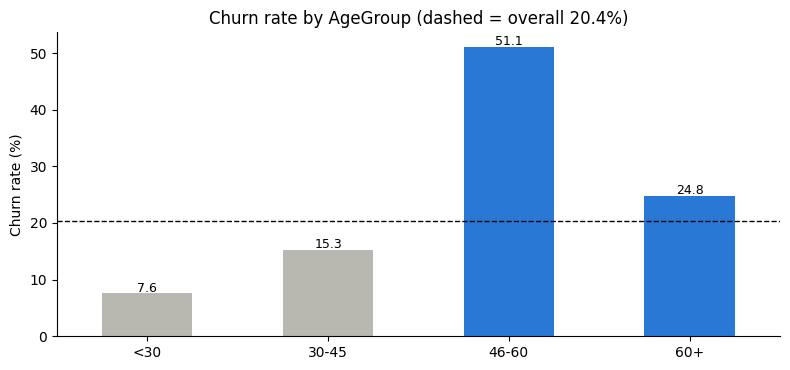

=== TenureGroup ===


,Customers,Churned,ChurnRate,ShareOfCustomers,ShareOfChurners,RiskIndex,AvgBalance,BalanceLost
TenureGroup,,,,,,,,
New (0-2y),2496,528,21.2,25.0,25.9,103.8,78054.0,46924795.4
Mid-term (3-6y),3977,821,20.6,39.8,40.3,101.3,75665.6,73678183.5
Long-term (7y+),3527,689,19.5,35.3,33.8,95.9,76301.1,65078133.2


Chi-square = 2.64, dof = 2, p-value = 0.2667, Cramer's V = 0.016 (negligible)
Verdict: no significant difference in churn across segments


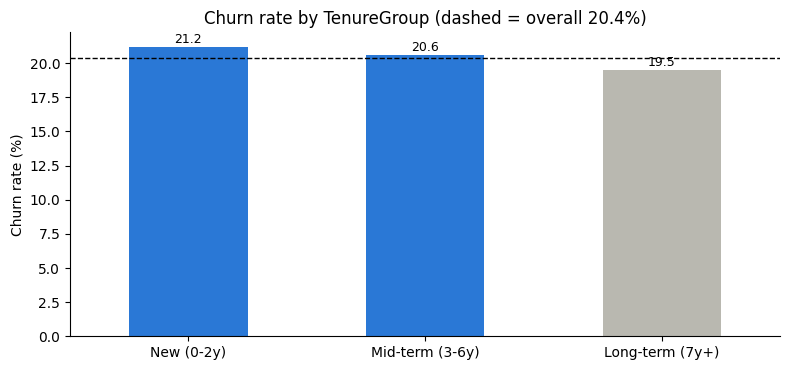

=== CreditBand ===


,Customers,Churned,ChurnRate,ShareOfCustomers,ShareOfChurners,RiskIndex,AvgBalance,BalanceLost
CreditBand,,,,,,,,
Low (<580),2362,520,22.0,23.6,25.5,108.0,75900.5,47116752.9
Medium (580-739),5759,1137,19.7,57.6,55.8,96.9,76101.4,102982649.5
High (740+),1879,381,20.3,18.8,18.7,99.5,78400.3,35581709.6


Chi-square = 5.34, dof = 2, p-value = 0.06909, Cramer's V = 0.023 (negligible)
Verdict: no significant difference in churn across segments


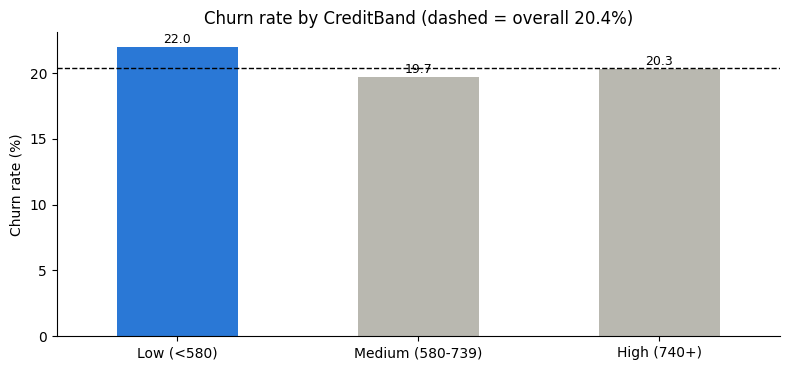

=== BalanceGroup ===


,Customers,Churned,ChurnRate,ShareOfCustomers,ShareOfChurners,RiskIndex,AvgBalance,BalanceLost
BalanceGroup,,,,,,,,
Zero,3617,500,13.8,36.2,24.5,67.8,0.0,0.0
Low (1-50k),75,26,34.7,0.8,1.3,170.1,39447.5,971840.3
Medium (50-100k),1509,301,19.9,15.1,14.8,97.9,83867.1,25219580.8
High (100k+),4799,1211,25.2,48.0,59.4,123.8,132391.1,159489691.0


Chi-square = 175.12, dof = 3, p-value = 9.972e-38, Cramer's V = 0.132 (moderate)
Verdict: churn DIFFERS across segments (significant)


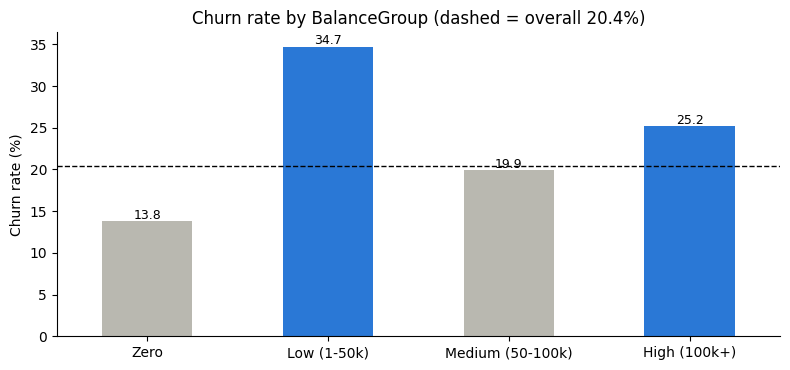

=== SalaryQuartile ===


,Customers,Churned,ChurnRate,ShareOfCustomers,ShareOfChurners,RiskIndex,AvgBalance,BalanceLost
SalaryQuartile,,,,,,,,
Q1 lowest,2500,500,20.0,25.0,24.5,98.1,75631.5,46454837.4
Q2,2500,495,19.8,25.0,24.3,97.2,75923.9,44277871.3
Q3,2500,503,20.1,25.0,24.7,98.7,77264.2,45939076.7
Q4 highest,2500,540,21.6,25.0,26.5,106.0,77123.9,49009326.8


Chi-square = 3.14, dof = 3, p-value = 0.3708, Cramer's V = 0.018 (negligible)
Verdict: no significant difference in churn across segments


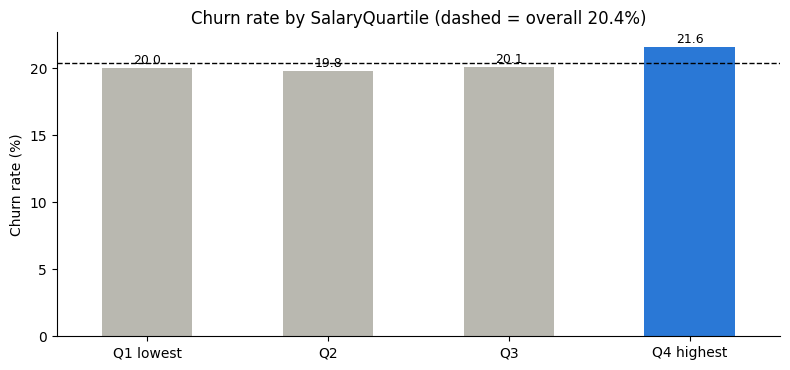

=== Activity ===


,Customers,Churned,ChurnRate,ShareOfCustomers,ShareOfChurners,RiskIndex,AvgBalance,BalanceLost
Activity,,,,,,,,
Active,5151,735,14.3,51.5,36.1,70.0,75875.4,67120667.8
Inactive,4849,1303,26.9,48.5,63.9,131.9,77134.4,118560444.3


Chi-square = 243.69, dof = 1, p-value = 6.153e-55, Cramer's V = 0.156 (moderate)
Verdict: churn DIFFERS across segments (significant)


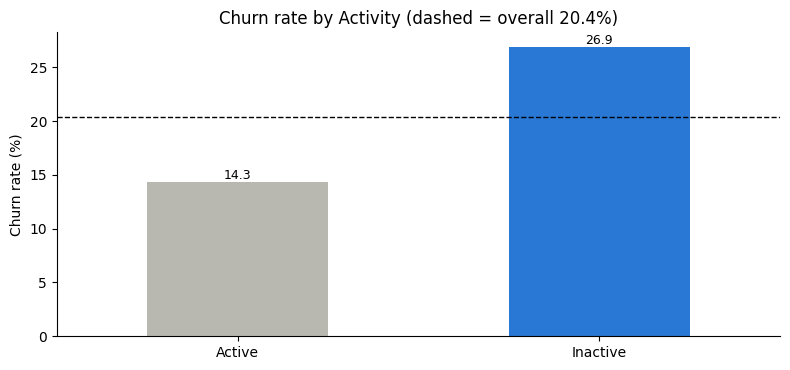

=== NumOfProducts ===


,Customers,Churned,ChurnRate,ShareOfCustomers,ShareOfChurners,RiskIndex,AvgBalance,BalanceLost
NumOfProducts,,,,,,,,
1,5084,1409,27.7,50.8,69.1,136.0,98551.9,129668607.1
2,4590,349,7.6,45.9,17.1,37.3,51879.1,31500837.8
3,266,220,82.7,2.7,10.8,405.8,75458.3,18887679.2
4,60,60,100.0,0.6,2.9,490.7,93733.1,5623988.1


Chi-square = 1501.5, dof = 3, p-value = 0, Cramer's V = 0.387 (strong)
Verdict: churn DIFFERS across segments (significant)


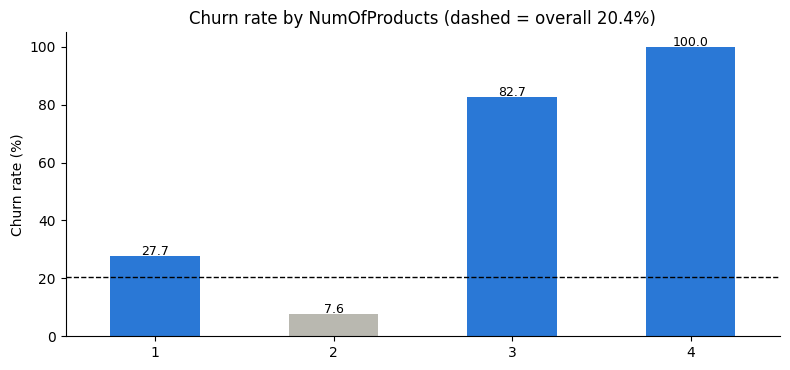

=== HasCrCard ===


,Customers,Churned,ChurnRate,ShareOfCustomers,ShareOfChurners,RiskIndex,AvgBalance,BalanceLost
HasCrCard,,,,,,,,
0,2945,613,20.8,29.4,30.1,102.1,77920.8,56352800.2
1,7055,1425,20.2,70.6,69.9,99.1,75886.9,129328311.9


Chi-square = 0.45, dof = 1, p-value = 0.5026, Cramer's V = 0.007 (negligible)
Verdict: no significant difference in churn across segments


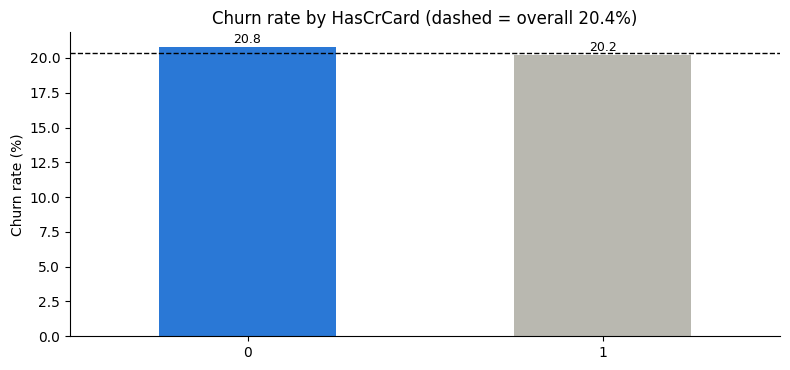

=== Satisfaction Score ===


,Customers,Churned,ChurnRate,ShareOfCustomers,ShareOfChurners,RiskIndex,AvgBalance,BalanceLost
Satisfaction Score,,,,,,,,
1,1932,387,20.0,19.3,19.0,98.3,77707.5,36015968.8
2,2014,439,21.8,20.1,21.5,107.0,75629.0,40218176.2
3,2042,401,19.6,20.4,19.7,96.4,76456.8,34843196.9
4,2008,414,20.6,20.1,20.3,101.2,75552.4,38670969.3
5,2004,397,19.8,20.0,19.5,97.2,77134.3,35932800.8


Chi-square = 3.8, dof = 4, p-value = 0.4334, Cramer's V = 0.02 (negligible)
Verdict: no significant difference in churn across segments


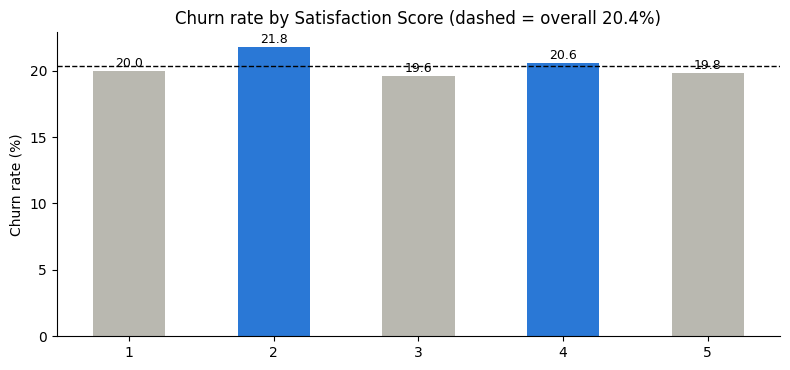

=== Card Type ===


,Customers,Churned,ChurnRate,ShareOfCustomers,ShareOfChurners,RiskIndex,AvgBalance,BalanceLost
Card Type,,,,,,,,
DIAMOND,2507,546,21.8,25.1,26.8,106.9,79120.0,50334627.0
GOLD,2502,482,19.3,25.0,23.7,94.5,76695.4,43009104.4
PLATINUM,2495,508,20.4,25.0,24.9,99.9,75692.7,45777065.9
SILVER,2496,502,20.1,25.0,24.6,98.7,74423.0,46560314.8


Chi-square = 5.05, dof = 3, p-value = 0.1679, Cramer's V = 0.022 (negligible)
Verdict: no significant difference in churn across segments


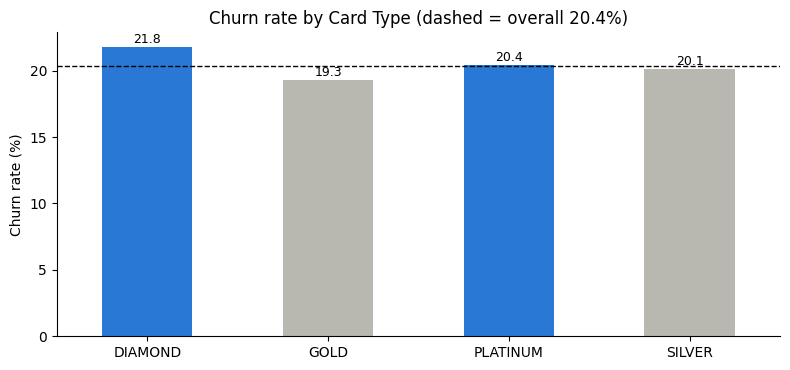

=== Complain ===


,Customers,Churned,ChurnRate,ShareOfCustomers,ShareOfChurners,RiskIndex,AvgBalance,BalanceLost
Complain,,,,,,,,
0,7956,4,0.1,79.6,0.2,0.2,72718.5,479682.1
1,2044,2034,99.5,20.4,99.8,488.3,91149.9,185201430.0


Chi-square = 9907.91, dof = 1, p-value = 0, Cramer's V = 0.995 (strong)
Verdict: churn DIFFERS across segments (significant)


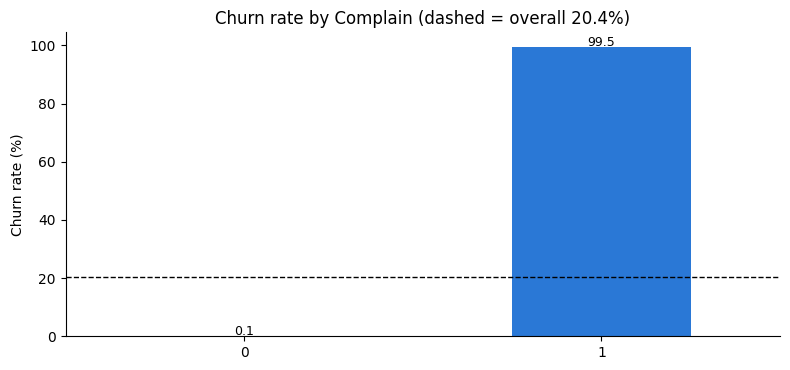

In [6]:
SEGMENT_FEATURES = ["Geography", "Gender", "AgeGroup", "TenureGroup", "CreditBand", "BalanceGroup", "SalaryQuartile",
                    "Activity", "NumOfProducts", "HasCrCard", "Satisfaction Score", "Card Type", "Complain"]
for feature in [f for f in SEGMENT_FEATURES if f in df.columns]:
    analyze(feature)

## Step 6. Summary of all chi-square tests
Ranks every feature by Cramér's V (strongest link to churn first).

**How to read it:** features near the top are most tied to churn; `Reliable = No` means too few customers in some cells to trust the test. A **Note** appears when a feature is almost a copy of the churn label (V above 0.90). That is **leakage**, not insight: such a field cannot be used to predict churn, and Step 12 removes it from the models.

In [7]:
summary_df = pd.DataFrame(RESULTS).sort_values(by="cramers_v", ascending=False).reset_index(drop=True)
summary_df["Note"] = np.where(summary_df.cramers_v > 0.90, "near copy of churn: leakage risk", "")
display(summary_df)

,Feature,Segments,ChurnRateMin,ChurnRateMax,chi2,dof,p_value,cramers_v,min_expected,cells_below_5_pct,Significant,Strength,Reliable,Note
0,Complain,2,0.1,99.5,9907.91,1,0.000000e+00,0.995,416.6,0.0,Yes,strong,Yes,near copy of churn: leakage risk
1,NumOfProducts,4,7.6,100.0,1501.50,3,0.000000e+00,0.387,12.2,0.0,Yes,strong,Yes,
2,AgeGroup,4,7.6,51.1,1229.89,3,2.403222e-266,0.351,94.6,0.0,Yes,strong,Yes,
3,Geography,3,16.2,32.4,300.63,2,5.245736e-66,0.173,504.8,0.0,Yes,moderate,Yes,
4,Activity,2,14.3,26.9,243.69,1,6.153167e-55,0.156,988.2,0.0,Yes,moderate,Yes,
5,BalanceGroup,4,13.8,34.7,175.12,3,9.972205e-38,0.132,15.3,0.0,Yes,moderate,Yes,
6,Gender,2,16.5,25.1,112.40,1,2.925368e-26,0.106,925.9,0.0,Yes,moderate,Yes,
7,CreditBand,3,19.7,22.0,5.34,2,6.908560e-02,0.023,382.9,0.0,No,negligible,Yes,
8,Card Type,4,19.3,21.8,5.05,3,1.679411e-01,0.022,508.5,0.0,No,negligible,Yes,
9,Satisfaction Score,5,19.6,21.8,3.80,4,4.333650e-01,0.020,393.7,0.0,No,negligible,Yes,


---
# Part C. Deeper analysis: profiles, interactions, high-value customers and KPIs
Part B tested each feature on its own. Part C completes the analysis plan.

## Step 7. Churned vs retained customers
Puts the two groups side by side.

- **Numeric fields:** the average for each group and the % difference (churned vs retained).
- **Category fields:** the share of each group in every category, and the gap in percentage points.

**How to read it:** a large positive difference means churners have *more* of this (for example a higher average age). A large gap in shares means that category is over-represented among churners.

Churn,Retained,Churned,Difference %
Age,37.41,44.84,19.86
CreditScore,651.84,645.41,-0.99
Tenure,5.03,4.93,-1.95
Balance,72742.75,91109.48,25.25
EstimatedSalary,99726.85,101509.91,1.79
NumOfProducts,1.54,1.48,-4.45
Satisfaction Score,3.02,3.00,-0.68
Point Earned,607.04,604.45,-0.43


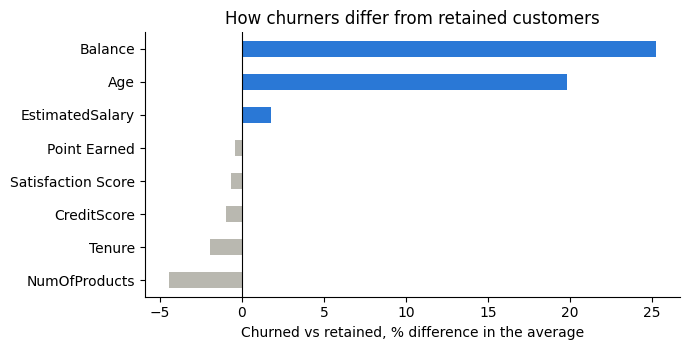

,Retained %,Churned %,Gap (points)
Geography = France,52.8,39.8,-13.0
Geography = Germany,21.3,39.9,18.7
Geography = Spain,25.9,20.3,-5.7
Gender = Female,42.8,55.9,13.1
Gender = Male,57.2,44.1,-13.1
Activity = Active,55.5,36.1,-19.4
Activity = Inactive,44.5,63.9,19.4
HasCrCard = 0,29.3,30.1,0.8
HasCrCard = 1,70.7,69.9,-0.8
NumOfProducts = 1,46.2,69.1,23.0


In [8]:
num = [c for c in ["Age", "CreditScore", "Tenure", "Balance", "EstimatedSalary", "NumOfProducts",
                   "Satisfaction Score", "Point Earned"] if c in df.columns]
prof = df.groupby("Churn")[num].mean().T.rename(columns={0: "Retained", 1: "Churned"})
prof["Difference %"] = (prof.Churned / prof.Retained - 1) * 100
display(prof.round(2))

ax = prof["Difference %"].sort_values().plot(kind="barh", figsize=(7, 3.6),
        color=[BLUE if v > 0 else GREY for v in prof["Difference %"].sort_values()])
ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("Churned vs retained, % difference in the average")
ax.set_title("How churners differ from retained customers"); plt.tight_layout(); plt.show()

cats = [c for c in ["Geography", "Gender", "Activity", "HasCrCard", "NumOfProducts", "Complain"] if c in df.columns]
parts = []
for c in cats:
    t = pd.crosstab(df[c], df.Churn, normalize="columns") * 100
    t.columns = ["Retained %", "Churned %"]
    t["Gap (points)"] = t["Churned %"] - t["Retained %"]
    t.index = [f"{c} = {i}" for i in t.index]
    parts.append(t)
display(pd.concat(parts).round(1))

## Step 8. Geography and age interaction
Does the effect of age differ from country to country? The table and heatmap show the churn rate for every country and age group together. Cells with fewer than 30 customers are blanked because their rates are unreliable.

**How to read it:** if each country shows the same pattern across age groups, there is no real interaction. A cell much darker than its row and column neighbours marks a specific pocket of risk. The last table shows, per country, the gap between its highest and lowest age group.

AgeGroup,<30,30-45,46-60,60+
Geography,,,,
France,5.2,11.9,45.8,19.9
Germany,12.6,25.3,67.3,38.9
Spain,7.9,12.5,40.7,20.8


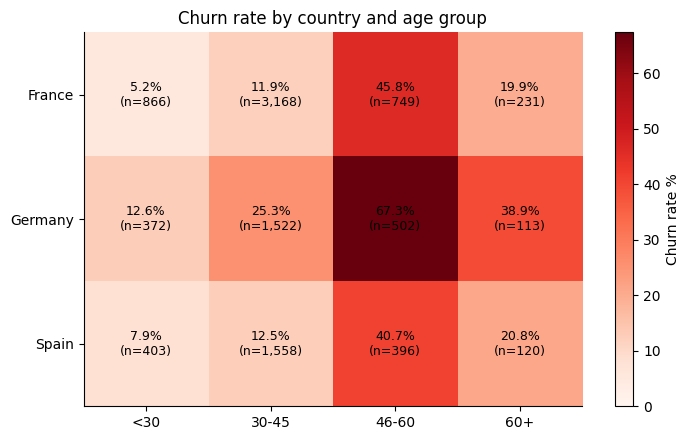

,Highest,Lowest,Gap (points),Highest age group
Geography,,,,
France,45.8,5.2,40.6,46-60
Germany,67.3,12.6,54.7,46-60
Spain,40.7,7.9,32.7,46-60


In [10]:
def heatmap(pt, cnt, title, min_n=30):
    data = pt.where(cnt >= min_n)
    fig, ax = plt.subplots(figsize=(7.5, 0.9 * len(pt) + 1.8))
    im = ax.imshow(data.values.astype(float), cmap="Reds", vmin=0)
    ax.set_xticks(range(data.shape[1]), [str(c) for c in data.columns])
    ax.set_yticks(range(data.shape[0]), [str(i) for i in data.index])
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            v = data.values[i, j]
            ax.text(j, i, "n<30" if pd.isna(v) else f"{v:.1f}%\n(n={int(cnt.values[i, j]):,})", ha="center", va="center", fontsize=9)
    ax.set_title(title); plt.colorbar(im, ax=ax, label="Churn rate %")
    plt.tight_layout(); plt.show()

def churn_grid(row, col):
    pt = df.pivot_table(index=row, columns=col, values="Churn", aggfunc="mean", observed=True) * 100
    cnt = df.pivot_table(index=row, columns=col, values="Churn", aggfunc="size", observed=True).fillna(0)
    return pt, cnt

pt, cnt = churn_grid("Geography", "AgeGroup")
display(pt.round(1))
heatmap(pt, cnt, "Churn rate by country and age group")

spread = pt.where(cnt >= 30)
gap = pd.DataFrame({"Highest": spread.max(axis=1), "Lowest": spread.min(axis=1)})
gap["Gap (points)"] = gap.Highest - gap.Lowest
gap["Highest age group"] = spread.idxmax(axis=1)
display(gap.round(1))

## Step 9. Financial stability vs churn
Financial stability is read from three signals: **credit score**, **balance** and **products held**. The heatmap crosses credit band with balance group, and the second table crosses credit band with number of products.

**How to read it:** look for the darkest cells. If churn is high for low credit *and* zero balance but not for either alone, the combination is what matters. If the colours barely change, financial standing does not explain churn much.

BalanceGroup,Zero,Low (1-50k),Medium (50-100k),High (100k+)
CreditBand,,,,
Low (<580),14.3,53.8,22.3,27.5
Medium (580-739),13.7,31.4,19.3,24.3
High (740+),13.6,27.3,19.0,25.3


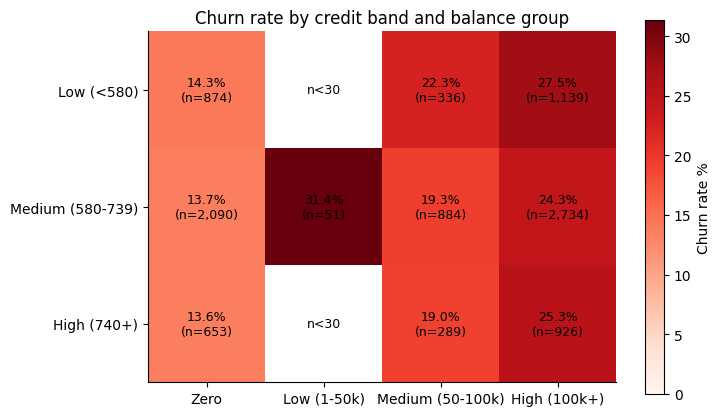

NumOfProducts,1,2,3,4
CreditBand,,,,
Low (<580),29.6,8.0,95.0,100.0
Medium (580-739),26.5,7.8,79.0,100.0
High (740+),29.0,6.5,79.6,100.0


In [11]:
pt, cnt = churn_grid("CreditBand", "BalanceGroup")
display(pt.round(1))
heatmap(pt, cnt, "Churn rate by credit band and balance group")

pt2, cnt2 = churn_grid("CreditBand", "NumOfProducts")
display(pt2.round(1))

## Step 10. High-value customers: high-balance churners, salary vs balance, and balance risk
**High-value** means a balance above `HIGH_VALUE_BALANCE` (set in Step 1).

1. **High-balance churners:** how many high-balance customers left, their share of all churners and of all lost money, and the 10 largest.
2. **Salary vs balance:** churn rate by salary quartile next to churn rate by balance group. If balance moves churn but salary does not, balance is the better lens.
3. **Balance risk:** the total account balance that left, and where it came from.

,Value
High-balance customers,4799.0
High-balance share of all customers %,48.0
High-balance churners,1211.0
High-balance churn rate %,25.2
Overall churn rate %,20.4
Share of all churners %,59.4
Balance lost from high-balance churners,159489691.0
Share of all lost balance %,85.9


The 10 largest balances among customers who left:


,CustomerId,Geography,Age,Balance,EstimatedSalary,NumOfProducts,Activity
0,15757408,Spain,38,250898.09,81054.00,3,Active
1,15715622,France,57,238387.56,147964.99,1,Active
2,15714241,Spain,42,222267.63,101108.85,1,Inactive
3,15586674,Spain,58,216109.88,74176.71,1,Active
4,15594408,Spain,48,213146.20,75161.25,1,Inactive
5,15671256,France,35,211774.31,188574.12,1,Inactive
6,15736420,France,21,210433.08,197297.77,2,Active
7,15721658,Spain,56,209767.31,150694.42,2,Active
8,15578671,Spain,29,209490.21,133267.69,1,Active
9,15709920,France,33,208165.53,50774.81,1,Inactive


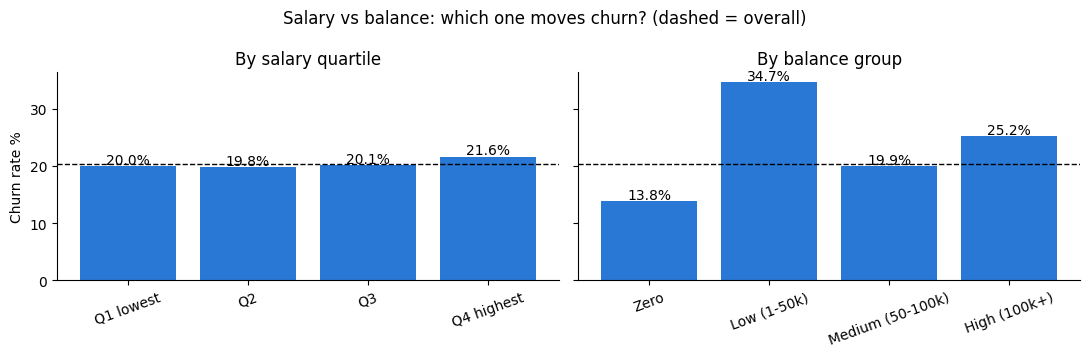

Correlation between balance and salary: 0.013

Balance that left: 185.7M of 764.9M (24.3% of all balance)


,Dimension,Customers,Churned,ChurnRate,BalanceLost,ShareOfBalanceLost %
France,Geography,5014,811,16.2,57759182.0,31.1
Germany,Geography,2509,814,32.4,97973915.5,52.8
Spain,Geography,2477,413,16.7,29948014.6,16.1
Active,Activity,5151,735,14.3,67120667.8,36.1
Inactive,Activity,4849,1303,26.9,118560444.3,63.9
Zero,BalanceGroup,3617,500,13.8,0.0,0.0
Low (1-50k),BalanceGroup,75,26,34.7,971840.3,0.5
Medium (50-100k),BalanceGroup,1509,301,19.9,25219580.8,13.6
High (100k+),BalanceGroup,4799,1211,25.2,159489691.0,85.9


In [26]:
hv_mask = df.Balance > HIGH_VALUE_BALANCE      # reused by the KPIs in Step 11
hv = df[hv_mask]
ch = df[df.Churn == 1]
hv_ch = hv[hv.Churn == 1]
summary = pd.Series({
    "High-balance customers": len(hv),
    "High-balance share of all customers %": len(hv) / len(df) * 100,
    "High-balance churners": len(hv_ch),
    "High-balance churn rate %": hv.Churn.mean() * 100,
    "Overall churn rate %": OVERALL,
    "Share of all churners %": len(hv_ch) / len(ch) * 100,
    "Balance lost from high-balance churners": hv_ch.Balance.sum(),
    "Share of all lost balance %": hv_ch.Balance.sum() / ch.Balance.sum() * 100,
})
display(summary.round(1).to_frame("Value"))

print("The 10 largest balances among customers who left:")
show = [c for c in [id_col, "Geography", "Age", "Balance", "EstimatedSalary", "NumOfProducts", "Activity"] if c and c in df.columns]
display(ch.sort_values("Balance", ascending=False)[show].head(10).reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, col, title in [(axes[0], "SalaryQuartile", "By salary quartile"), (axes[1], "BalanceGroup", "By balance group")]:
    r = df.groupby(col, observed=True).Churn.mean() * 100
    ax.bar(r.index.astype(str), r.values, color=BLUE)
    ax.axhline(OVERALL, ls="--", color="black", lw=1)
    ax.set_title(title); ax.tick_params(axis="x", rotation=20)
    for i, v in enumerate(r.values): ax.text(i, v + 0.4, f"{v:.1f}%", ha="center")
axes[0].set_ylabel("Churn rate %")
plt.suptitle("Salary vs balance: which one moves churn? (dashed = overall)"); plt.tight_layout(); plt.show()
print("Correlation between balance and salary:", round(df.Balance.corr(df.EstimatedSalary), 3))

total_bal, lost_bal = df.Balance.sum(), ch.Balance.sum()
print(f"\nBalance that left: {lost_bal/1e6:.1f}M of {total_bal/1e6:.1f}M ({lost_bal/total_bal*100:.1f}% of all balance)")

rows = []
for col in ["Geography", "Activity", "BalanceGroup"]:
    g = df.groupby(col, observed=True).agg(Customers=("Churn", "size"), Churned=("Churn", "sum"), ChurnRate=("Churn", "mean"))
    g["BalanceLost"] = ch.groupby(col, observed=True).Balance.sum()
    g["ShareOfBalanceLost %"] = g.BalanceLost / lost_bal * 100
    g["ChurnRate"] = g.ChurnRate * 100
    g.insert(0, "Dimension", col)
    rows.append(g)
display(pd.concat(rows).round(1))

## Step 11. The five KPIs
| KPI | Definition used here |
|---|---|
| **Overall Churn Rate** | customers who exited ÷ all customers (Step 3) |
| **Segment Churn Rate** | churn % for each segment, with the highest and lowest segment per dimension (tables from Step 5) |
| **High-Value Churn Ratio** | churn rate of high-value customers ÷ overall churn rate (above 1 means premium customers leave *more* than average). Premium = balance above `HIGH_VALUE_BALANCE`, and also platinum / diamond cardholders if the file has `Card Type` |
| **Geographic Risk Index** | a country's churn rate ÷ overall churn rate × 100 (100 = average, above 100 = riskier) |
| **Engagement Drop Indicator** | churn rate of inactive members ÷ churn rate of active members, plus the extra churners that inactivity accounts for |

**How to read it:** the summary table at the end gives all five on one screen. These KPIs describe association, not cause.

KPI 2. Segment churn rate: highest and lowest segment in each dimension


,Highest segment,Highest %,Lowest segment,Lowest %,Spread (points)
Dimension,,,,,
AgeGroup,46-60,51.1,<30,7.6,43.5
BalanceGroup,Low (1-50k),34.7,Zero,13.8,20.9
Geography,Germany,32.4,France,16.2,16.2
Activity,Inactive,26.9,Active,14.3,12.6
Gender,Female,25.1,Male,16.5,8.6
CreditBand,Low (<580),22.0,Medium (580-739),19.7,2.3
TenureGroup,New (0-2y),21.2,Long-term (7y+),19.5,1.7



KPI 3. High-Value Churn Ratio


,Premium definition,Customers,Churn rate %,High-Value Churn Ratio
0,"Balance above 100,000",4799,25.23,1.24
1,Platinum / Diamond card,5002,21.07,1.03



KPI 4. Geographic Risk Index (100 = average)


,Customers,Churned,ChurnRate,Geographic Risk Index,ShareOfChurners
Geography,,,,,
France,5014,811,16.2,79.4,39.8
Germany,2509,814,32.4,159.2,39.9
Spain,2477,413,16.7,81.8,20.3


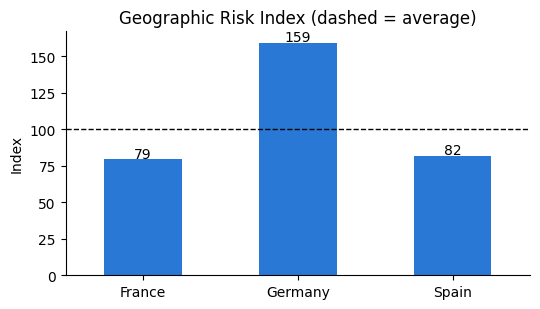


KPI 5. Engagement Drop Indicator: inactive 26.9% vs active 14.3% (ratio 1.88x); about 611 extra churners are linked to inactivity

The five KPIs


,KPI,Value,Meaning
0,Overall Churn Rate,20.4%,customers who exited
1,Segment Churn Rate,7.6% to 51.1%,lowest to highest segment
2,High-Value Churn Ratio,1.24 | 1.03,premium churn rate / overall (1 = same as aver...
3,Geographic Risk Index,"France 79, Germany 159, Spain 82",country churn rate / overall x 100
4,Engagement Drop Indicator,1.88x (26.9% vs 14.3%),inactive churn rate / active churn rate


In [13]:
# KPI 2: highest and lowest segment in every dimension (tables built in Step 5)
dims = [c for c in ["Geography", "Gender", "AgeGroup", "CreditBand", "TenureGroup", "BalanceGroup", "Activity"] if c in SEG_TABLES]
rows = [{"Dimension": c, "Segment": str(seg), "Customers": int(r.Customers), "ChurnRate %": r.ChurnRate}
        for c in dims for seg, r in SEG_TABLES[c].iterrows()]
seg_kpi = pd.DataFrame(rows)
top_seg = seg_kpi.loc[seg_kpi.groupby("Dimension")["ChurnRate %"].idxmax()].set_index("Dimension")
low_seg = seg_kpi.loc[seg_kpi.groupby("Dimension")["ChurnRate %"].idxmin()].set_index("Dimension")
seg_summary = pd.DataFrame({"Highest segment": top_seg.Segment, "Highest %": top_seg["ChurnRate %"],
                            "Lowest segment": low_seg.Segment, "Lowest %": low_seg["ChurnRate %"]})
seg_summary["Spread (points)"] = seg_summary["Highest %"] - seg_summary["Lowest %"]
print("KPI 2. Segment churn rate: highest and lowest segment in each dimension")
display(seg_summary.sort_values("Spread (points)", ascending=False).round(1))

# KPI 3: high-value churn ratio (hv_mask comes from Step 10)
premium = {f"Balance above {HIGH_VALUE_BALANCE:,}": hv_mask}
if "Card Type" in df.columns:
    card_mask = df["Card Type"].astype(str).str.upper().isin(["PLATINUM", "DIAMOND"])
    if card_mask.sum() > 0:
        premium["Platinum / Diamond card"] = card_mask
hv_kpi = pd.DataFrame([{"Premium definition": name, "Customers": int(m.sum()), "Churn rate %": df.loc[m, "Churn"].mean() * 100,
                        "High-Value Churn Ratio": df.loc[m, "Churn"].mean() * 100 / OVERALL} for name, m in premium.items()])
print("\nKPI 3. High-Value Churn Ratio")
display(hv_kpi.round(2))

# KPI 4: geographic risk index (RiskIndex was already computed in Step 5)
geo = SEG_TABLES["Geography"][["Customers", "Churned", "ChurnRate", "RiskIndex", "ShareOfChurners"]].rename(
    columns={"RiskIndex": "Geographic Risk Index"})
print("\nKPI 4. Geographic Risk Index (100 = average)")
display(geo.round(1))
ax = geo["Geographic Risk Index"].plot(kind="bar", color=BLUE, rot=0, figsize=(5.5, 3.2))
ax.axhline(100, ls="--", color="black", lw=1); ax.set_ylabel("Index"); ax.set_xlabel("")
ax.set_title("Geographic Risk Index (dashed = average)")
for i, v in enumerate(geo["Geographic Risk Index"]): ax.text(i, v + 1, f"{v:.0f}", ha="center")
plt.tight_layout(); plt.show()

# KPI 5: engagement drop indicator
act = SEG_TABLES["Activity"]
inactive_rate, active_rate = act.loc["Inactive", "ChurnRate"], act.loc["Active", "ChurnRate"]
extra = (inactive_rate - active_rate) / 100 * act.loc["Inactive", "Customers"]
print(f"\nKPI 5. Engagement Drop Indicator: inactive {inactive_rate:.1f}% vs active {active_rate:.1f}% "
      f"(ratio {inactive_rate/active_rate:.2f}x); about {extra:.0f} extra churners are linked to inactivity")

# all five on one screen
geo_text = ", ".join(f"{k} {v:.0f}" for k, v in geo["Geographic Risk Index"].items())
kpi_table = pd.DataFrame([
    ["Overall Churn Rate", f"{OVERALL:.1f}%", "customers who exited"],
    ["Segment Churn Rate", f"{seg_kpi['ChurnRate %'].min():.1f}% to {seg_kpi['ChurnRate %'].max():.1f}%", "lowest to highest segment"],
    ["High-Value Churn Ratio", " | ".join(f"{r['High-Value Churn Ratio']:.2f}" for _, r in hv_kpi.iterrows()), "premium churn rate / overall (1 = same as average)"],
    ["Geographic Risk Index", geo_text, "country churn rate / overall x 100"],
    ["Engagement Drop Indicator", f"{inactive_rate/active_rate:.2f}x ({inactive_rate:.1f}% vs {active_rate:.1f}%)", "inactive churn rate / active churn rate"],
], columns=["KPI", "Value", "Meaning"])
print("\nThe five KPIs")
display(kpi_table)

---
# Part D. Prediction models: train, compare and check errors
Part D trains **five different models**, compares them on the same hidden test customers, and counts the mistakes of the best one with a **confusion matrix**.

## Step 12. Choose the features and check for leakage
**Features:** the row and customer identifiers, the surname, the target (`Churn`, and its twin `Exited`) and the grouped fields from Step 4 are removed. The grouped fields only repeat the original columns.

**Leakage check:** a column that almost *equals* the answer makes a model look perfect (an AUC near 1.0) without being useful, because the bank would not have that information *before* a customer decides to leave. For every feature the code measures how strongly it is tied to churn on its own: **Cramér's V** for categories and yes/no fields, **single-feature AUC** for numbers. Anything above the limits (V above 0.90 or AUC above 0.95) is removed.

**How to read it:** the table lists the five strongest single features. A normal feature has a V below about 0.25.

In [14]:
NOT_FEATURES = [c for c in ["RowNumber", "CustomerId", "CustomerID", "Surname", "Churn", "Exited"] + GROUPED if c in df.columns]
X = df.drop(columns=NOT_FEATURES)
y = df["Churn"]
print("Removed:", NOT_FEATURES)

def leakage_check(X, y, v_limit=0.90, auc_limit=0.95):
    rows = []
    for c in X.columns:
        s = X[c]
        if s.dtype.kind in "if" and s.nunique() > 10:
            a = roc_auc_score(y, s)
            score, kind, limit = max(a, 1 - a), "single-feature AUC", auc_limit
        else:
            ct = pd.crosstab(s, y)
            if ct.shape[0] < 2:
                continue
            score = cramers_v_from(chi2_contingency(ct)[0], ct.values.sum(), ct.shape)
            kind, limit = "Cramers V", v_limit
        rows.append({"Feature": c, "Measure": kind, "Score": round(score, 3), "Limit": limit, "Leaky": score > limit})
    return pd.DataFrame(rows).sort_values("Score", ascending=False).reset_index(drop=True)

leak = leakage_check(X, y)
display(leak.head(5))
LEAKY = leak.loc[leak.Leaky, "Feature"].tolist()
if LEAKY:
    print("LEAKAGE FOUND, removing:", LEAKY)
    X = X.drop(columns=LEAKY)
else:
    print("No leaky features found.")
print("Features used by the models:", X.columns.tolist())

Removed: ['RowNumber', 'CustomerId', 'Churn', 'Exited', 'AgeGroup', 'CreditBand', 'TenureGroup', 'BalanceGroup', 'SalaryQuartile', 'Activity']


,Feature,Measure,Score,Limit,Leaky
0,Complain,Cramers V,0.995,0.90,True
1,Age,single-feature AUC,0.732,0.95,False
2,Balance,single-feature AUC,0.578,0.95,False
3,CreditScore,single-feature AUC,0.516,0.95,False
4,Tenure,single-feature AUC,0.510,0.95,False


LEAKAGE FOUND, removing: ['Complain']
Features used by the models: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Satisfaction Score', 'Card Type', 'Point Earned']


## Step 13. Prepare the data, split train / test and define five models
- **Numeric** columns are scaled and **text** columns are one-hot encoded inside a *pipeline*, so the same preparation is applied automatically whenever a model is used.
- **20% of customers are hidden** as a test set. `stratify=y` keeps the churn rate the same in both parts. Never choose or tune anything using the test set.

| Model | Idea | Why include it |
|---|---|---|
| Logistic Regression | a weighted score added up | simple and easy to explain |
| Decision Tree | a chain of yes/no questions | very readable rules |
| Random Forest | many trees voting | handles complex patterns |
| Gradient Boosting | trees built one after another to fix mistakes | often the most accurate on tables |
| K-Nearest Neighbors | looks at the 25 most similar customers | a very different approach |

`class_weight="balanced"` makes the first three models pay extra attention to churners, who are the minority.

In [15]:
numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
print("Numeric:", numeric_features)
print("Categorical:", categorical_features)

def make_preprocessor(scale=True):
    return ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
print(f"\nTrain: {len(X_train):,} customers (churn {y_train.mean()*100:.1f}%) | Test: {len(X_test):,} customers (churn {y_test.mean()*100:.1f}%)")

models = {
    "Logistic Regression": Pipeline([("prep", make_preprocessor(True)),
                                     ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "Decision Tree": Pipeline([("prep", make_preprocessor(False)),
                               ("clf", DecisionTreeClassifier(max_depth=5, min_samples_leaf=30,
                                                              class_weight="balanced", random_state=SEED))]),
    "Random Forest": Pipeline([("prep", make_preprocessor(False)),
                               ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                              class_weight="balanced", n_jobs=-1, random_state=SEED))]),
    "Gradient Boosting": Pipeline([("prep", make_preprocessor(False)),
                                   ("clf", GradientBoostingClassifier(random_state=SEED))]),
    "K-Nearest Neighbors": Pipeline([("prep", make_preprocessor(True)),
                                     ("clf", KNeighborsClassifier(n_neighbors=25))]),
}
print("Models:", list(models))

Numeric: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Satisfaction Score', 'Point Earned']
Categorical: ['Geography', 'Gender', 'Card Type']

Train: 8,000 customers (churn 20.4%) | Test: 2,000 customers (churn 20.4%)
Models: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'K-Nearest Neighbors']


## Step 14. Train all five and score them on the test set
For each model the code runs **5-fold cross-validation** on the training data (a stable AUC), **trains** on the full training set, predicts churn probabilities for the hidden test customers, turns them into yes/no with `THRESHOLD` (Step 1), and counts the four outcomes of the **confusion matrix**:

| Outcome | Meaning |
|---|---|
| **TN** true negative | predicted to stay, and stayed |
| **FP** false positive | predicted to leave, but **stayed** (a wasted retention offer) |
| **FN** false negative | predicted to stay, but **left** (a churner we missed) |
| **TP** true positive | predicted to leave, and left (a churner caught) |

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

test_prob, rows = {}, []
for name, pipe in models.items():
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc").mean()
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    pred = (p >= THRESHOLD).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    test_prob[name] = p
    rows.append({
        "Model": name,
        "CV AUC": cv_auc,
        "Train AUC": roc_auc_score(y_train, pipe.predict_proba(X_train)[:, 1]),
        "Test AUC": roc_auc_score(y_test, p),
        "PR-AUC": average_precision_score(y_test, p),
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "FalsePositiveRate": fp / (fp + tn),
        "Specificity (TN rate)": tn / (tn + fp),
    })
    print(f"trained {name}")

comparison = pd.DataFrame(rows).set_index("Model")

trained Logistic Regression
trained Decision Tree
trained Random Forest
trained Gradient Boosting
trained K-Nearest Neighbors


## Step 15. Compare the models and draw the ROC curves
All five models side by side on the same hidden test customers.

- **Test AUC:** how well the model ranks churners above stayers (0.5 = guessing, 1.0 = perfect). **The main score, because the classes are unequal.** The best model is chosen by it.
- **Train AUC vs Test AUC:** a big gap means **overfitting** (memorising the training data).
- **Precision:** of customers flagged as leaving, the share who really leave. **Recall:** of customers who really leave, the share we catch.
- **Accuracy** can mislead: predicting "nobody leaves" is already about 80% accurate when churn is about 20%.
- **ROC curve:** the further a curve rises above the diagonal, the better the model separates churners from stayers.

,CV AUC,Train AUC,Test AUC,PR-AUC,Accuracy,Precision,Recall,F1
Model,,,,,,,,
Gradient Boosting,0.862,0.888,0.877,0.728,0.870,0.777,0.505,0.612
Random Forest,0.855,0.984,0.867,0.693,0.852,0.633,0.654,0.643
Decision Tree,0.826,0.845,0.849,0.661,0.772,0.466,0.787,0.585
K-Nearest Neighbors,0.816,0.867,0.819,0.587,0.830,0.813,0.213,0.338
Logistic Regression,0.766,0.769,0.780,0.474,0.712,0.389,0.723,0.506


Best model by Test AUC: Gradient Boosting (0.877)


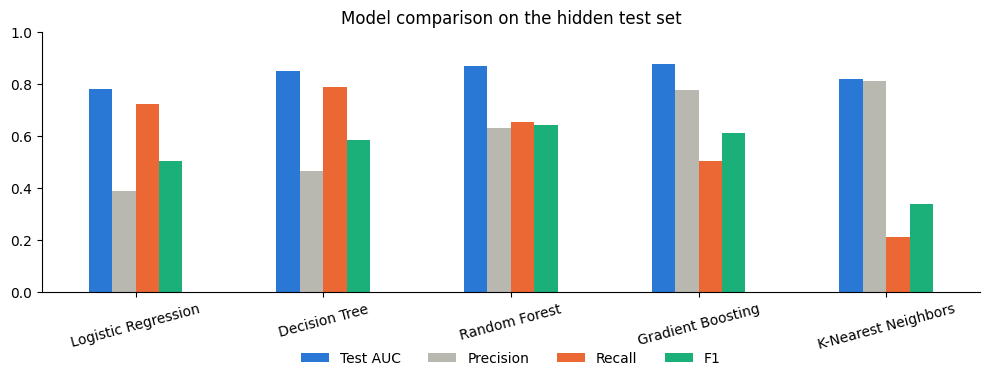

In [17]:
metric_cols = ["CV AUC", "Train AUC", "Test AUC", "PR-AUC", "Accuracy", "Precision", "Recall", "F1"]
display(comparison[metric_cols].sort_values("Test AUC", ascending=False).round(3))

best_name = comparison["Test AUC"].idxmax()
print(f"Best model by Test AUC: {best_name} ({comparison.loc[best_name, 'Test AUC']:.3f})")

ax = comparison[["Test AUC", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(10, 4), rot=15,
        color=["#2a78d6", "#b9b8b0", "#eb6834", "#1baf7a"])
ax.set_title("Model comparison on the hidden test set"); ax.set_xlabel(""); ax.set_ylim(0, 1)
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18))
plt.tight_layout(); plt.show()

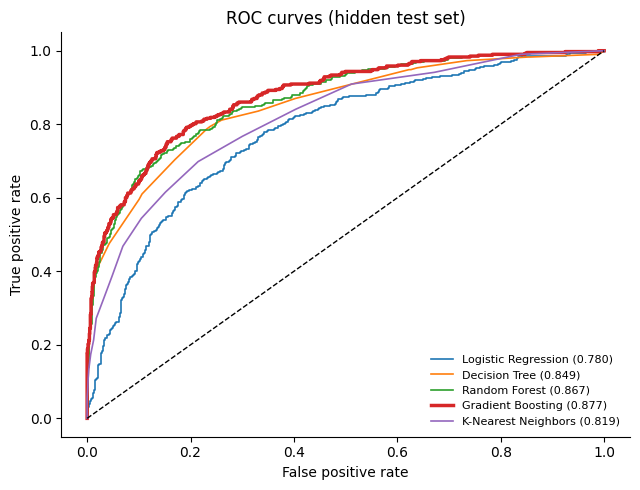

Final model: Gradient Boosting at threshold 0.5
              precision    recall  f1-score   support

      Stayed      0.884     0.963     0.922      1592
        Left      0.777     0.505     0.612       408

    accuracy                          0.870      2000
   macro avg      0.830     0.734     0.767      2000
weighted avg      0.862     0.870     0.858      2000



In [18]:
plt.figure(figsize=(6.5, 5))
for name, p in test_prob.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, lw=2.5 if name == best_name else 1.2, label=f"{name} ({roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "--", color="black", lw=1)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curves (hidden test set)")
plt.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

final_model = models[best_name]
pred_best = (test_prob[best_name] >= THRESHOLD).astype(int)
print(f"Final model: {best_name} at threshold {THRESHOLD}")
print(classification_report(y_test, pred_best, target_names=["Stayed", "Left"], digits=3))

## Step 16. Confusion matrix and threshold for the best model
The four counts for the **best model only** (chosen in Step 15), with the two rates that matter most for false alarms:

- **False Positive Rate (FPR)** = FP ÷ (FP + TN): of customers who **stayed**, the share wrongly flagged as leaving.
- **Specificity (TN rate)** = TN ÷ (TN + FP): the share of stayers correctly left alone (1 − FPR).

**How to read the matrix:** top-left is TN, top-right is **FP**, bottom-left is **FN**, bottom-right is TP. Many FP means retention offers wasted on customers who would have stayed; many FN means missed churners.

**The threshold table:** a **lower** threshold flags more customers (fewer FN, but more FP and fewer TN); a **higher** threshold does the opposite. Pick the row that matches your budget for offers. The row with the highest **F1** balances precision and recall.

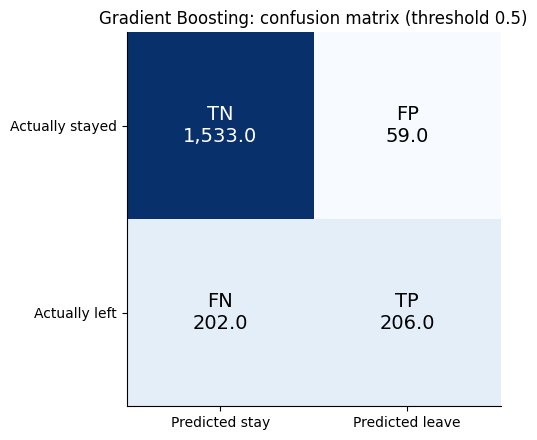

True negatives  (stayed, left alone):          1,533
False positives (stayed, wrongly flagged):     59  -> false positive rate 3.7%
False negatives (left, missed):                202
True positives  (left, correctly flagged):     206  -> recall 50.5%
Specificity (share of stayers left alone):     96.3%


In [19]:
r = comparison.loc[best_name]
cm = np.array([[r.TN, r.FP], [r.FN, r.TP]])
labels = [["TN", "FP"], ["FN", "TP"]]

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{labels[i][j]}\n{cm[i, j]:,}", ha="center", va="center", fontsize=14,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["Predicted stay", "Predicted leave"]); ax.set_yticks([0, 1], ["Actually stayed", "Actually left"])
ax.set_title(f"{best_name}: confusion matrix (threshold {THRESHOLD})")
plt.tight_layout(); plt.show()

print(f"True negatives  (stayed, left alone):          {int(r.TN):,}")
print(f"False positives (stayed, wrongly flagged):     {int(r.FP):,}  -> false positive rate {r.FalsePositiveRate*100:.1f}%")
print(f"False negatives (left, missed):                {int(r.FN):,}")
print(f"True positives  (left, correctly flagged):     {int(r.TP):,}  -> recall {r.Recall*100:.1f}%")
print(f"Specificity (share of stayers left alone):     {r['Specificity (TN rate)']*100:.1f}%")

In [20]:
p_best = test_prob[best_name]
rows = []
for t in np.arange(0.10, 0.91, 0.05):
    pred = (p_best >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    rows.append({"Threshold": round(t, 2), "Flagged": int(pred.sum()), "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                 "Precision": round(precision_score(y_test, pred, zero_division=0), 3),
                 "Recall": round(recall_score(y_test, pred), 3), "F1": round(f1_score(y_test, pred), 3)})
thr_table = pd.DataFrame(rows)
display(thr_table)
BEST_F1_THRESHOLD = float(thr_table.loc[thr_table.F1.idxmax(), "Threshold"])
print(f"Threshold with the best F1 for {best_name}: {BEST_F1_THRESHOLD}")

,Threshold,Flagged,TN,FP,FN,TP,Precision,Recall,F1
0,0.10,1088,877,715,35,373,0.343,0.914,0.499
1,0.15,787,1148,444,65,343,0.436,0.841,0.574
2,0.20,625,1288,304,87,321,0.514,0.787,0.621
3,0.25,500,1381,211,119,289,0.578,0.708,0.637
4,0.30,441,1421,171,138,270,0.612,0.662,0.636
5,0.35,386,1457,135,157,251,0.650,0.615,0.632
6,0.40,340,1488,104,172,236,0.694,0.578,0.631
7,0.45,297,1517,75,186,222,0.747,0.544,0.630
8,0.50,265,1533,59,202,206,0.777,0.505,0.612
9,0.55,229,1549,43,222,186,0.812,0.456,0.584


Threshold with the best F1 for Gradient Boosting: 0.25


## Step 17 (optional). SHAP: why does the model score customers as risky?
**SHAP** gives every feature a score for every customer: how much it **pushed that customer's churn risk up (positive) or down (negative)**.

- **Bar chart:** features ranked by average impact.
- **Dot chart:** one dot per customer. Dots to the **right** raised risk. Red dots are a **high** value of the feature, blue a **low** value.

**Nothing after this step depends on it** It installs the `shap` library the first time and is computed on a sample of test customers to keep it fast. Like everything here it shows **association, not cause**.

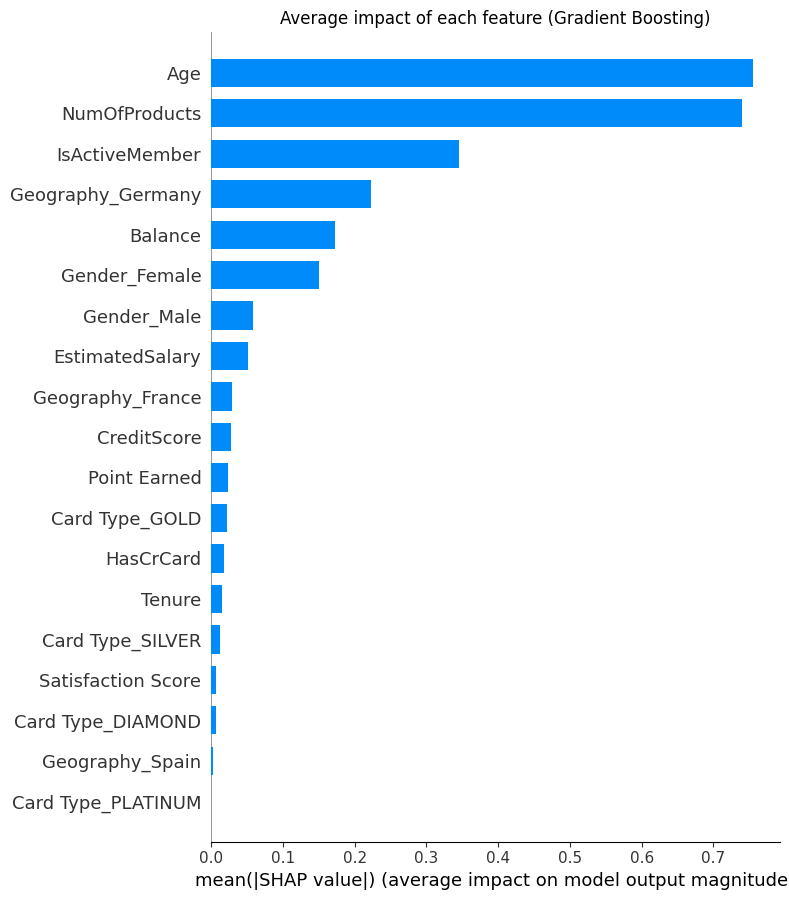

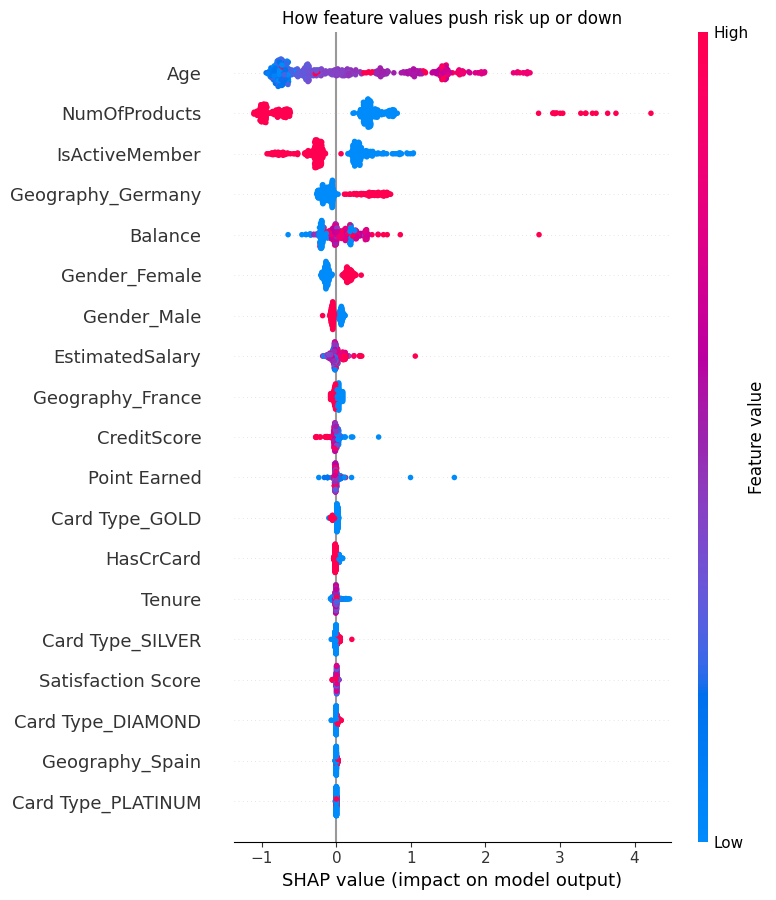

,Mean |SHAP|
Age,0.7549
NumOfProducts,0.7398
IsActiveMember,0.3449
Geography_Germany,0.2227
Balance,0.1731
Gender_Female,0.1498
Gender_Male,0.0577
EstimatedSalary,0.0508
Geography_France,0.0292
CreditScore,0.0275


In [21]:
import sys, subprocess
try:
    import shap
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap

prep, clf = final_model.named_steps["prep"], final_model.named_steps["clf"]

def to_dense(m):
    return m.toarray() if hasattr(m, "toarray") else np.asarray(m)

feat_names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
Xt_train = to_dense(prep.transform(X_train))
sample = X_test.sample(min(500, len(X_test)), random_state=SEED)
Xt = to_dense(prep.transform(sample))

if best_name == "Logistic Regression":
    explainer = shap.LinearExplainer(clf, Xt_train)
    sv = explainer.shap_values(Xt)
elif best_name == "K-Nearest Neighbors":
    background = shap.kmeans(Xt_train, 20)
    explainer = shap.KernelExplainer(lambda d: clf.predict_proba(d)[:, 1], background)
    sv = explainer.shap_values(Xt[:100], nsamples=100)
    Xt = Xt[:100]
else:
    explainer = shap.TreeExplainer(clf)
    sv = explainer.shap_values(Xt)

if isinstance(sv, list):          # older shap: one array per class
    sv = sv[1]
sv = np.asarray(sv)
if sv.ndim == 3:                  # newer shap: (rows, features, classes)
    sv = sv[:, :, 1]

shap.summary_plot(sv, Xt, feature_names=feat_names, plot_type="bar", show=False)
plt.title(f"Average impact of each feature ({best_name})"); plt.tight_layout(); plt.show()

shap.summary_plot(sv, Xt, feature_names=feat_names, show=False)
plt.title("How feature values push risk up or down"); plt.tight_layout(); plt.show()

shap_importance = (pd.Series(np.abs(sv).mean(axis=0), index=feat_names)
                   .sort_values(ascending=False).rename("Mean |SHAP|").to_frame())
display(shap_importance.head(10).round(4))

---
# Part E. High-risk customers: find, analyse and export
## Step 18. Score every customer and check the risk tiers
Every customer gets a **churn probability** from the best model. **Honest scoring:** `cross_val_predict` scores each customer with a model that **never saw that customer**.

**Risk tiers** are set by rank: **High** is the top `HIGH_RISK_SHARE` of customers, **Medium** the next `MEDIUM_RISK_SHARE`, **Low** the rest (both set in Step 1).

**Does the tier work?** The table checks the tiers against what **actually** happened. If the model works, actual churn rises from Low to High. **Lift** compares a tier with the overall rate (2 = twice the average churn). **% of all churners** shows how many real churners are reached by contacting only the High tier.

RiskTier
Low       5000
Medium    3000
High      2000
Name: count, dtype: int64


,Customers,Churned,ActualChurnRate,AvgProbability,TotalBalance,ExpectedBalanceAtRisk,Lift,% of all churners
RiskTier,,,,,,,,
High,2000,1269,63.45,0.62,1.835122e+08,114122404.0,3.11,62.27
Medium,3000,547,18.23,0.18,2.798125e+08,50621500.0,0.89,26.84
Low,5000,222,4.44,0.05,3.015342e+08,20528861.0,0.22,10.89


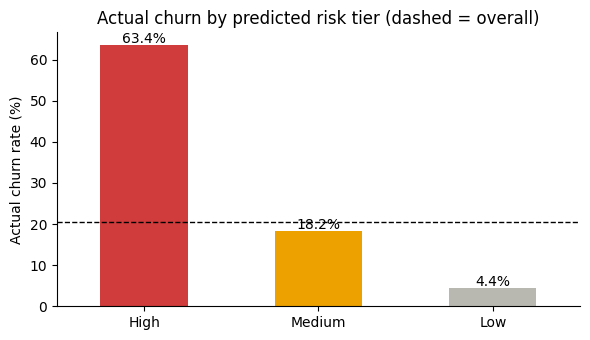

High-risk group: 2,000 customers (20% of all)
  catches 62.3% of all churners; 63.4% of them actually left
  total balance 183.5M; expected balance at risk 114.1M


In [22]:
oof = cross_val_predict(clone(models[best_name]), X, y, cv=cv, method="predict_proba")[:, 1]

scored = df.copy()
scored["ChurnProbability"] = oof.round(4)
rank_pct = scored.ChurnProbability.rank(pct=True, ascending=False, method="first")
scored["RiskTier"] = np.where(rank_pct <= HIGH_RISK_SHARE, "High",
                      np.where(rank_pct <= HIGH_RISK_SHARE + MEDIUM_RISK_SHARE, "Medium", "Low"))
scored["ExpectedBalanceAtRisk"] = (scored.ChurnProbability * scored.Balance).round(0)
print(scored.RiskTier.value_counts())

tier = scored.groupby("RiskTier").agg(
    Customers=("Churn", "size"), Churned=("Churn", "sum"), ActualChurnRate=("Churn", "mean"),
    AvgProbability=("ChurnProbability", "mean"), TotalBalance=("Balance", "sum"),
    ExpectedBalanceAtRisk=("ExpectedBalanceAtRisk", "sum"),
).loc[["High", "Medium", "Low"]]
tier["Lift"] = tier.ActualChurnRate / BASE_RATE
tier["% of all churners"] = tier.Churned / tier.Churned.sum() * 100
tier["ActualChurnRate"] = tier.ActualChurnRate * 100
display(tier.round(2))

ax = tier.ActualChurnRate.plot(kind="bar", color=["#d03b3b", "#eda100", "#b9b8b0"], rot=0, figsize=(6, 3.5))
ax.axhline(BASE_RATE * 100, ls="--", color="black", lw=1)
ax.set_ylabel("Actual churn rate (%)"); ax.set_xlabel(""); ax.set_title("Actual churn by predicted risk tier (dashed = overall)")
for i, v in enumerate(tier.ActualChurnRate): ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")
plt.tight_layout(); plt.show()

high_group = scored[scored.RiskTier == "High"]
print(f"High-risk group: {len(high_group):,} customers ({len(high_group)/len(scored)*100:.0f}% of all)")
print(f"  catches {high_group.Churn.sum()/scored.Churn.sum()*100:.1f}% of all churners; {high_group.Churn.mean()*100:.1f}% of them actually left")
print(f"  total balance {high_group.Balance.sum()/1e6:.1f}M; expected balance at risk {high_group.ExpectedBalanceAtRisk.sum()/1e6:.1f}M")

## Step 19. Who are the high-risk customers, and why?
1. **Numeric profile:** the average of each numeric field for High-risk and everyone else, with the % difference.
2. **Over-represented segments:** categories **more common** among High-risk customers than in the whole base (`Ratio` above 1.2 = at least 20% over-represented).
3. **Risk drivers per customer:** the segments each customer belongs to where the actual churn rate is at least **1.25 times the average** (and the segment has at least 100 customers). Example: `IsActiveMember=0; NumOfProducts=1`.

> Drivers are **descriptive**: they show which known risk segments a customer falls into, not what caused the churn.

In [23]:
rest = scored[scored.RiskTier != "High"]
num_cols_profile = [c for c in numeric_features if c in scored.columns]
profile = pd.DataFrame({"High risk": high_group[num_cols_profile].mean(), "Everyone else": rest[num_cols_profile].mean()})
profile["Difference %"] = (profile["High risk"] / profile["Everyone else"] - 1) * 100
display(profile.round(2))

cat_like = categorical_features + [c for c in numeric_features if scored[c].nunique() <= 8]
rows = []
for c in cat_like:
    share_hi = high_group[c].value_counts(normalize=True)
    share_all = scored[c].value_counts(normalize=True)
    for seg, s in share_hi.items():
        rows.append({"Feature": c, "Segment": seg, "% of high-risk": s * 100, "% of all customers": share_all[seg] * 100,
                     "Ratio": s / share_all[seg], "HighRiskCustomers": int(round(s * len(high_group)))})
over = pd.DataFrame(rows)
over = over[(over.Ratio >= 1.2) & (over.HighRiskCustomers >= 30)].sort_values("Ratio", ascending=False)
print("Segments over-represented among high-risk customers:")
display(over.round(2).reset_index(drop=True))

driver_features = [c for c in X.columns]
seg_labels = pd.DataFrame(index=X.index)
for c in driver_features:
    s = X[c]
    seg_labels[c] = pd.qcut(s, 4, duplicates="drop").astype(str) if (s.dtype.kind in "if" and s.nunique() > 8) else s.astype(str)

risky_segments = {}
for c in seg_labels:
    g = y.groupby(seg_labels[c]).agg(["mean", "size"])
    risky_segments[c] = set(g[(g["mean"] >= 1.25 * BASE_RATE) & (g["size"] >= 100)].index)

drivers = pd.Series("", index=X.index)
for c, segs in risky_segments.items():
    m = seg_labels[c].isin(segs)
    drivers[m] = drivers[m] + c + "=" + seg_labels.loc[m, c] + "; "
scored["RiskDrivers"] = drivers.str.rstrip("; ").replace("", "none")

print("Risky segments found:")
for c, segs in risky_segments.items():
    if segs: print(f"  {c}: {sorted(segs)}")

,High risk,Everyone else,Difference %
CreditScore,642.81,652.46,-1.48
Age,47.81,36.70,30.29
Tenure,4.95,5.03,-1.65
Balance,91756.09,72668.34,26.27
NumOfProducts,1.44,1.55,-6.90
HasCrCard,0.70,0.71,-0.35
IsActiveMember,0.31,0.57,-44.66
EstimatedSalary,101400.84,99762.59,1.64
Satisfaction Score,3.05,3.00,1.49
Point Earned,606.22,606.59,-0.06


Segments over-represented among high-risk customers:


,Feature,Segment,% of high-risk,% of all customers,Ratio,HighRiskCustomers
0,NumOfProducts,4,3.00,0.60,5.00,60
1,NumOfProducts,3,12.95,2.66,4.87,259
2,Geography,Germany,45.55,25.09,1.82,911
3,NumOfProducts,1,74.50,50.84,1.47,1490
4,IsActiveMember,0,68.70,48.49,1.42,1374
5,Gender,Female,58.55,45.43,1.29,1171


Risky segments found:
  Geography: ['Germany']
  Age: ['(44.0, 92.0]']
  Balance: ['(97198.54, 127644.24]']
  NumOfProducts: ['1', '3']
  IsActiveMember: ['0']


## Step 20. Export the high-risk customers to CSV
| File | Content |
|---|---|
| `high_risk_customers.csv` | only the **High-risk** customers, with probability, expected balance at risk (probability × balance), risk drivers and key fields, sorted so the **biggest money at risk is first** |
| `all_customer_risk_scores.csv` | every customer with their probability and tier |
| `churn_model.joblib` | the trained best model, to reuse later |

`ActualChurn` is included to check the model against what really happened. Surnames are left out. In Colab the two CSVs download to your computer.

In [24]:
keep_cols = [c for c in [id_col, "Geography", "Gender", "Age", "Tenure", "CreditScore", "Balance", "EstimatedSalary",
                         "NumOfProducts", "HasCrCard", "IsActiveMember", "Satisfaction Score", "Card Type", "Point Earned"]
             if c and c in scored.columns]

out_cols = keep_cols + ["ChurnProbability", "RiskTier", "ExpectedBalanceAtRisk", "RiskDrivers"]
high_risk = (scored[scored.RiskTier == "High"][out_cols + ["Churn"]]
             .rename(columns={"Churn": "ActualChurn"})
             .sort_values("ExpectedBalanceAtRisk", ascending=False))
high_risk.insert(0, "PriorityRank", range(1, len(high_risk) + 1))

high_risk.to_csv("high_risk_customers.csv", index=False)
scored[out_cols + ["Churn"]].rename(columns={"Churn": "ActualChurn"}).to_csv("all_customer_risk_scores.csv", index=False)
joblib.dump(final_model, "churn_model.joblib")

print(f"Saved high_risk_customers.csv ({len(high_risk):,} customers), all_customer_risk_scores.csv and churn_model.joblib")
display(high_risk.head(15))
try:
    from google.colab import files
    for f in ["high_risk_customers.csv", "all_customer_risk_scores.csv"]:
        files.download(f)
except ImportError:
    pass

Saved high_risk_customers.csv (2,000 customers), all_customer_risk_scores.csv and churn_model.joblib


,PriorityRank,CustomerId,Geography,Gender,Age,Tenure,CreditScore,Balance,EstimatedSalary,NumOfProducts,HasCrCard,IsActiveMember,Satisfaction Score,Card Type,Point Earned,ChurnProbability,RiskTier,ExpectedBalanceAtRisk,RiskDrivers,ActualChurn
2092,1,15757408,Spain,Male,38,3,655,250898.09,81054.00,3,0,1,1,SILVER,336,0.9837,High,246808.0,NumOfProducts=3,1
8683,2,15599329,France,Female,49,7,697,195238.29,131083.56,4,0,1,2,GOLD,503,0.9737,High,190104.0,"Age=(44.0, 92.0]",1
138,3,15594408,Spain,Female,48,2,584,213146.20,75161.25,1,1,0,4,DIAMOND,814,0.8412,High,179299.0,"Age=(44.0, 92.0]; NumOfProducts=1; IsActiveMem...",1
8188,4,15623314,Germany,Female,59,3,506,190353.08,78365.75,1,1,0,4,PLATINUM,797,0.9130,High,173792.0,"Geography=Germany; Age=(44.0, 92.0]; NumOfProd...",0
6567,5,15593425,Spain,Female,54,1,662,187997.15,111442.71,1,0,0,4,SILVER,857,0.9093,High,170946.0,"Age=(44.0, 92.0]; NumOfProducts=1; IsActiveMem...",1
1341,6,15609824,France,Female,41,7,794,176845.41,166526.26,3,1,0,5,GOLD,226,0.9634,High,170373.0,NumOfProducts=3; IsActiveMember=0,1
4784,7,15811588,Spain,Female,53,7,664,187602.18,186392.99,1,1,0,2,SILVER,712,0.9027,High,169348.0,"Age=(44.0, 92.0]; NumOfProducts=1; IsActiveMem...",1
5114,8,15721460,France,Male,60,8,678,185648.56,192156.54,1,0,0,2,PLATINUM,508,0.9075,High,168476.0,"Age=(44.0, 92.0]; NumOfProducts=1; IsActiveMem...",1
4166,9,15654562,Spain,Female,45,5,850,174088.30,5669.31,4,1,0,1,GOLD,240,0.9622,High,167508.0,"Age=(44.0, 92.0]; IsActiveMember=0",1
2462,10,15704442,France,Female,53,9,672,169406.33,147311.47,4,1,1,4,DIAMOND,232,0.9835,High,166611.0,"Age=(44.0, 92.0]",1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# How to read the results
1. **Step 6:** the strongest features sit at the top. A Note on a field means it is almost a copy of churn (leakage), not a finding.
2. **Steps 7-11:** how churners differ, where the risk sits (country, age, money) and the five KPIs.
3. **Step 15:** the model with the highest **Test AUC** wins. If several are within about 0.01, prefer the simpler one.
4. **Step 16:** use the **FP** and **TN** counts to see false alarms, and choose a threshold that matches your budget for offers.
5. **Steps 18-20:** act on the **High** tier, starting with the largest `ExpectedBalanceAtRisk`, and use `RiskDrivers` to choose the action for each customer.

**Limits.** A moderate AUC means the model ranks groups of customers usefully but cannot call any single customer with certainty. The data is a single snapshot, so results show association, not cause, and there is no revenue field, so balance stands in for money at risk. Retrain regularly on fresh data.

# Glossary
| Term | Meaning |
|---|---|
| Chi-square test / p-value | tests whether churn really differs between groups; below 0.05 = unlikely to be chance |
| Cramér's V | strength of the link between a feature and churn: 0 none, 1 perfect |
| Risk index | a segment's churn rate ÷ overall rate × 100 (100 = average) |
| True negative (TN) | predicted to stay and stayed |
| False positive (FP) | predicted to leave but stayed: a wasted offer |
| False negative (FN) | predicted to stay but left: a missed churner |
| True positive (TP) | predicted to leave and left |
| False positive rate | FP ÷ (FP + TN): share of stayers wrongly flagged |
| Specificity | TN ÷ (TN + FP): share of stayers correctly left alone |
| Precision / Recall | of those flagged, the share who leave / of all who leave, the share caught |
| ROC-AUC | how well the model ranks churners above stayers: 0.5 = guessing, 1.0 = perfect |
| Leakage | using information the bank would not have before the customer decides |
| Lift | a group's churn rate divided by the overall rate |